# Playground
- this notebook is meant for a general overview on the project and downloading the data
- some analysis on the data and some examples can be found
- discarded code, initial implementations, incomplete ideas are dumped here

In [1]:
import numpy as np
import os
import gdown
import subprocess
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict
from PIL import Image
import cv2
import random
import glob
from pathlib import Path
from torch.utils.data import Dataset
from torch.utils.data import DataLoader

# import seaborn as sns
plt.style.use('default')
plt.rcParams['figure.figsize'] = [10, 10]

/tmp/ipykernel_7435/2931744971.py:5: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


# 2. Download data

In [2]:
def downloader(From = "https://drive.google.com/open?id=18EunmjOJsbE5Lh9zA0cZ4wKV6Um46dkg",
               To = "/home/kia/Desktop/PoD/NNDL/data/"):

    """
    Downloads a folder from Google Drive to a specified local directory.

    Parameters
    ----------
    From : str, optional
        URL of the Google Drive folder to download. Default is a sample folder URL.
    To : str, optional
        Path to the local directory where the folder will be downloaded. Default is 
        '/home/kia/Desktop/PoD/NNDL/data/'.

    Returns
    -------
    None
        Downloads the folder to the specified location.
    """


    # Folder link and destination directory
    folder_url = From
    destination = To

    # Create destination directory if it doesn't exist
    os.makedirs(destination, exist_ok=True)

    # Download folder recursively
    gdown.download_folder(folder_url, quiet=False, output=destination)

In [3]:
def combine_zips(input_zip, output_zip, directory="/home/kia/Desktop/PoD/NNDL/data/"):
    
    """
    Combines split zip files using the `zip -F` command.

    Parameters
    ----------
    input_zip : str
        Path to the main split zip file (e.g., `data.zip`).
    output_zip : str
        Path for the combined output zip file.
    directory : str, optional
        Path to the directory containing the split zip parts. If None, assumes the current directory.

    Returns
    -------
    None
    """

    
    command = ["zip", "-F", input_zip, "--out", output_zip]
    
    if directory:
        command = ["cd", directory, "&&"] + command  
    
    try:
        subprocess.run(" ".join(command), shell=True, check=True)
        print(f"Combined ZIP file saved as {output_zip}")
    except subprocess.CalledProcessError as e:
        print(f"Error combining ZIP files: {e}")


In [4]:
def unzip_file(zip_file, password, directory):

    """
    Extracts a ZIP file using a password in quiet mode.

    Parameters
    ----------
    zip_file : str
        Path to the ZIP file.
    password : str
        Password for the ZIP file.
    directory : str
        Directory to extract the files to and from.

    Raises
    ------
    subprocess.CalledProcessError
        If the `unzip` command fails.
    """
    
    zip_file = os.path.join(directory, zip_file)
    try:
        command = [
            "unzip", "-q", "-P", password, zip_file, "-d", directory
        ]
        
        subprocess.run(command, check=True)
        print(f"Successfully unzipped {zip_file} to {directory}")
    
    except subprocess.CalledProcessError as e:
        print(f"Error during unzip: {e}")



## 2.1 Download, Combine and Unzip dataset

In [5]:
# Define working directory.
ROOT_DIR = os.getcwd()
DATA_FOLDER = "data"

In [6]:

try:
    os.listdir(os.path.join(ROOT_DIR, DATA_FOLDER))
    print("Data folder exists.")
except:
    os.mkdir(os.path.join(ROOT_DIR, DATA_FOLDER))

try:
    os.listdir(os.path.join(ROOT_DIR, DATA_FOLDER, "CompCars"))
    print("CompCars folder exists.")

except:
    print("Downloading dataset...")
    downloader(To = os.path.join(ROOT_DIR, DATA_FOLDER))
    print("Download complete.")
    print("Merging files...")
    combine_zips("sv_data.zip", "sv_combined.zip", os.path.join(ROOT_DIR, DATA_FOLDER, "CompCars"))
    print("Merging complete.")
    print("Unzipping files...")
    unzip_file("sv_combined.zip", "d89551fd190e38", os.path.join(ROOT_DIR, DATA_FOLDER, "CompCars"))
    print("Unzipping complete.")

Data folder exists.
CompCars folder exists.


### overview

In [7]:
view_dict = {-1:"uncertain", 1:"front", 2:"rear", 3:"side", 4:"front-side", 5:"rear-side"}

LAB_DIR = os.path.join(ROOT_DIR, "data/CompCars/data/label/")
IMG_DIR = os.path.join(ROOT_DIR, "data/CompCars/data/image/")
SPLITS_DIR = os.path.join(ROOT_DIR, "data/CompCars/data/train_test_split/verification/")

image_paths = np.array([file for file in Path(IMG_DIR).rglob('*') if file.is_file()])
label_paths = np.array([file for file in Path(LAB_DIR).rglob('*') if file.is_file()])
makes = np.array([image_paths[i].parts[-4] for i in range(len(image_paths))])
models = np.array([image_paths[i].parts[-3] for i in range(len(image_paths))])
views = np.array([open(label_paths[i], 'r').read().strip()[0] for i in range(len(label_paths))])


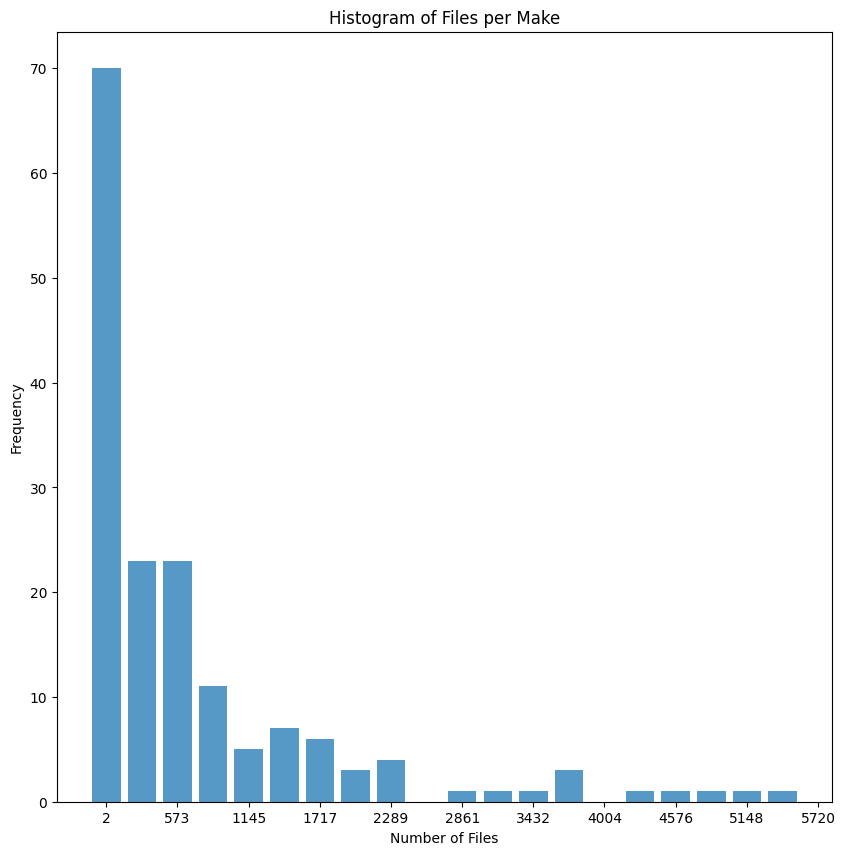

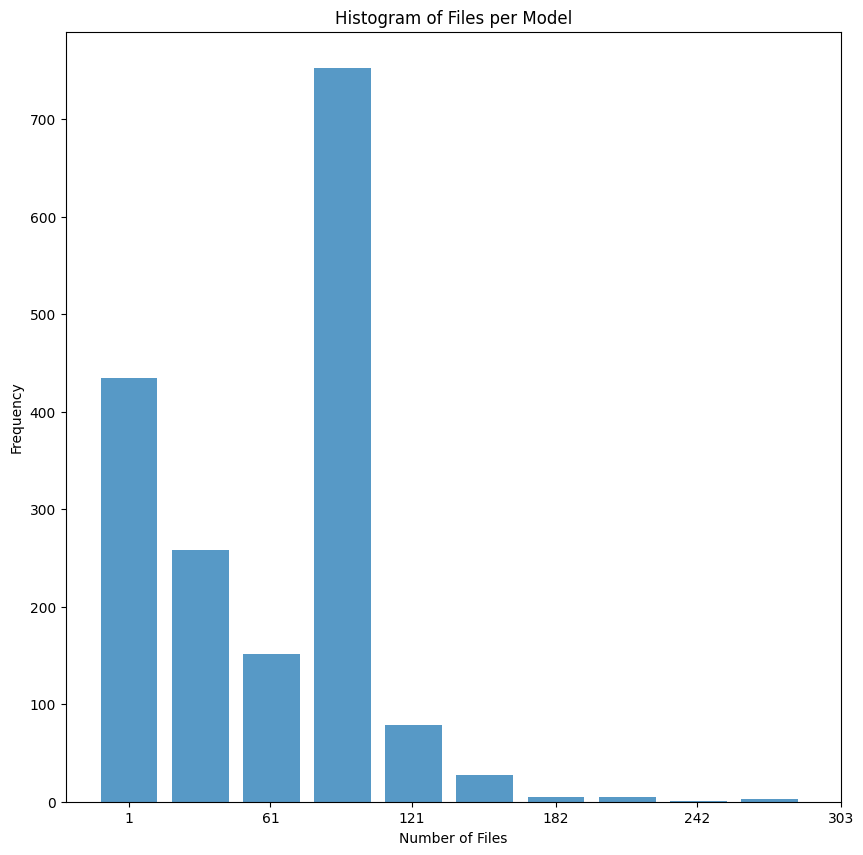

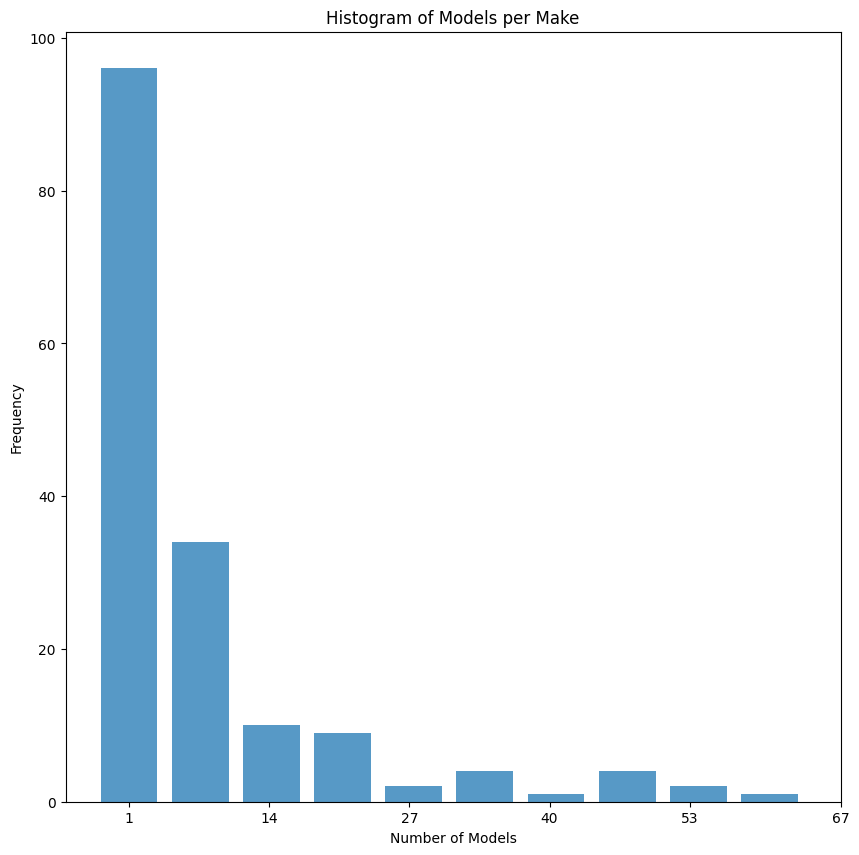

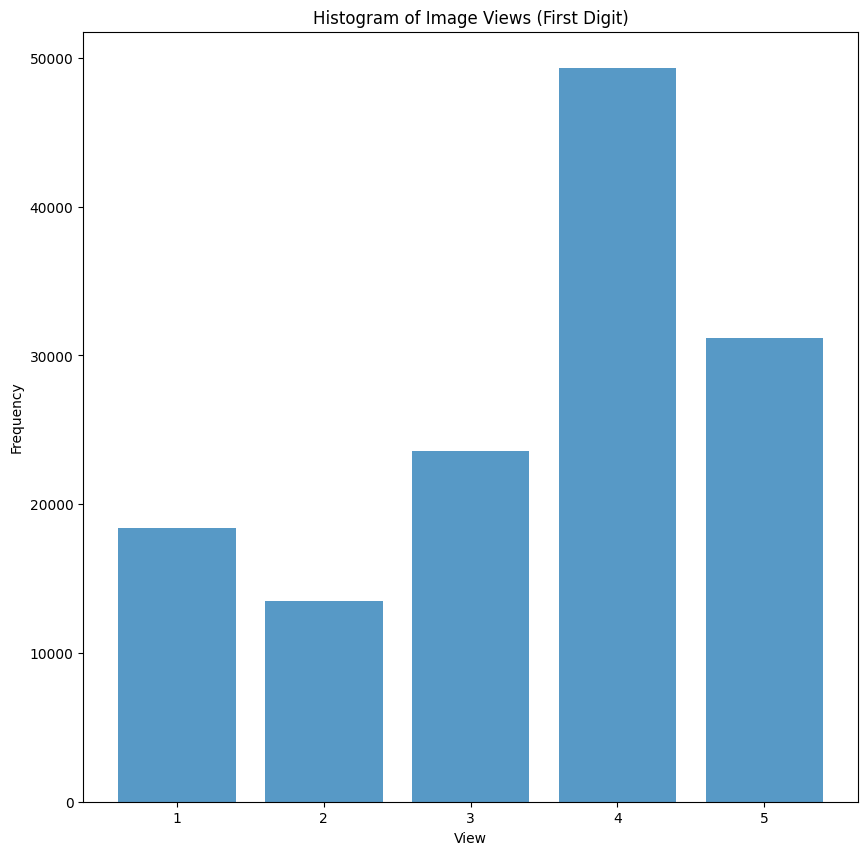

Number of files: 136726


In [9]:
# Initialize data structures to hold counts
files_per_make = defaultdict(int)
files_per_model = defaultdict(int)
models_per_make = defaultdict(set)

# Data for histogram
views = []

# Walk through the directory structure

for root, dirs, files in os.walk(LAB_DIR):
    path_parts = root.split(os.sep)
    
    # Identify make and model from the path
    if len(path_parts) >= len(LAB_DIR.split(os.sep))+2:
        make = path_parts[-3]
        model = path_parts[-2]
        
        # Update counts
        files_per_make[make] += len(files)
        files_per_model[model] += len(files)
        models_per_make[make].add(model)
        
        # Read data from description.txt files
        for file in files:
            file_path = os.path.join(root, file)
            with open(file_path, 'r') as f:
                content = f.read().strip()
                # Extract the first digit (view of the image)
                if content and content[0].isdigit():
                    views.append(int(content[0]))

# Convert sets to counts
models_per_make = {k: len(v) for k, v in models_per_make.items()}

fpmake = files_per_make.values()
plt.hist(fpmake, bins=100,align='left', rwidth=0.8, alpha=0.75)
plt.title('Histogram of Files per Make')
plt.xlabel('Number of Files')
plt.ylabel('Frequency')
plt.xticks(np.linspace(min(fpmake), max(fpmake),11, dtype=int)) 
plt.show()

fpmodel = files_per_model.values()
plt.hist(fpmodel, bins=40,align='left', rwidth=0.8, alpha=0.75)
plt.title('Histogram of Files per Model')
plt.xlabel('Number of Files')
plt.ylabel('Frequency')
plt.xticks(np.linspace(min(fpmodel), max(fpmodel),6, dtype=int))
plt.show()

modpmak = models_per_make.values()
plt.hist(modpmak, bins=30, align='left', rwidth=0.8, alpha=0.75)
plt.title('Histogram of Models per Make')
plt.xlabel('Number of Models')
plt.ylabel('Frequency')
plt.xticks(np.linspace(min(modpmak), max(modpmak),6, dtype=int))
plt.show()

# Plot histogram of views
plt.hist(views, bins=np.arange(6)+1, align='left', rwidth=0.8, alpha=0.75)
plt.title('Histogram of Image Views (First Digit)')
plt.xlabel('View')
plt.ylabel('Frequency')
plt.xticks(np.arange(1,6,1))
plt.show()

print("Number of files:", len(image_paths))


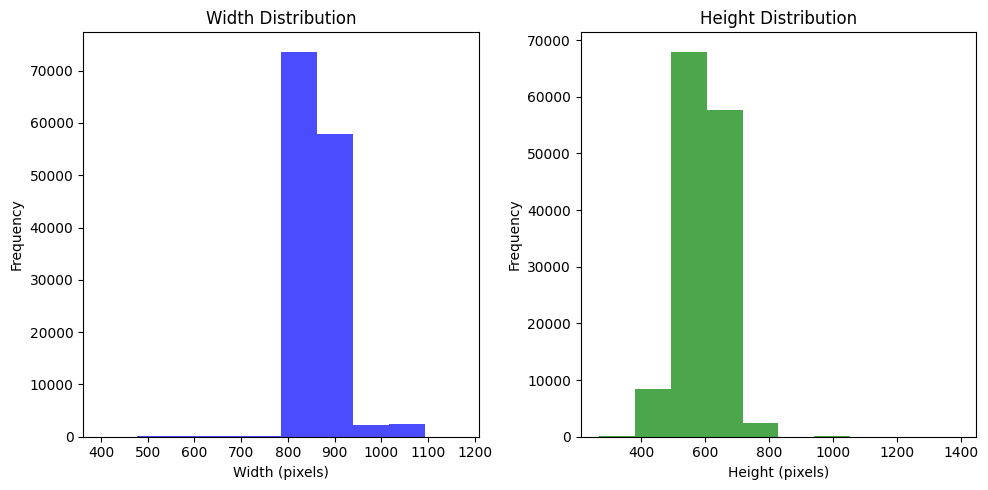

Number of unique resolutions: 485


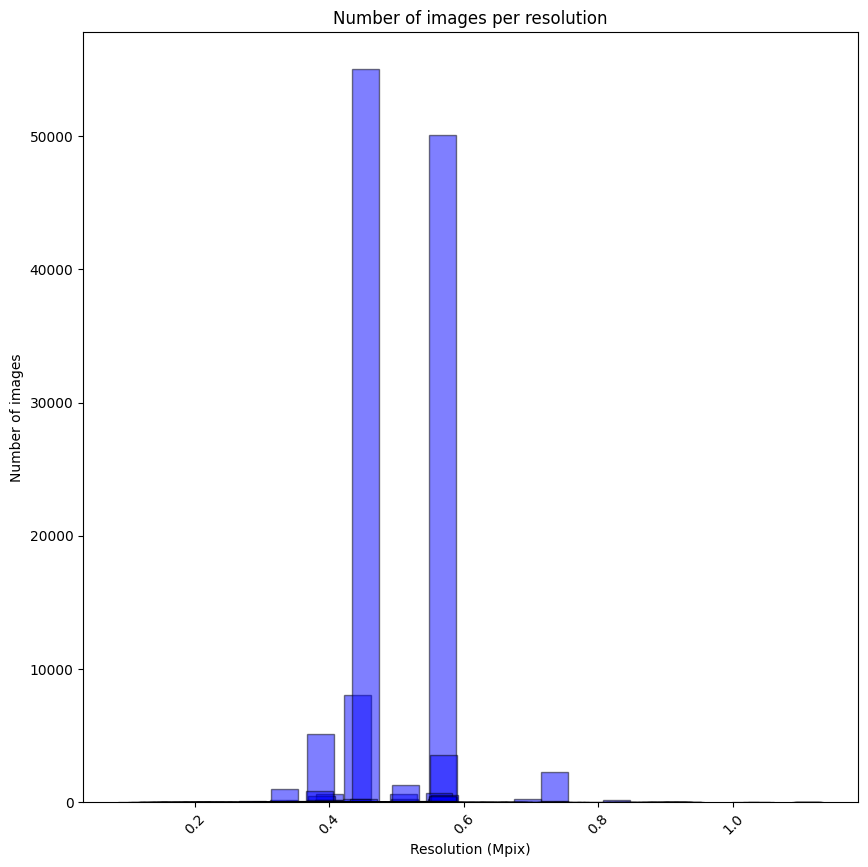

In [10]:
widths = []
heights = []
files_per_resolution = defaultdict(set)

# Traverse the directory
for root, dirs, files in os.walk(IMG_DIR):
    for file in files:
        file_path = os.path.join(root, file)
        try:
            # Open image using PIL
            with Image.open(file_path) as img:
                widths.append(img.width)
                heights.append(img.height)
                files_per_resolution[(img.width, img.height)].add(file)
        except Exception as e:
            print(f"Could not process file {file_path}: {e}")


files_per_resolution = {k: len(v) for k, v in files_per_resolution.items()}
# files_per_resolution = {k: len(v) for k, v in files_per_resolution.items()}

# Plot histogram of resolutions
plt.figure(figsize=(10, 5))

# Create width and height histograms
plt.subplot(1, 2, 1)
plt.hist(widths, bins=10, color='blue', alpha=0.7)
plt.title('Width Distribution')
plt.xlabel('Width (pixels)')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2)
plt.hist(heights, bins=10, color='green', alpha=0.7)
plt.title('Height Distribution')
plt.xlabel('Height (pixels)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


print(f"Number of unique resolutions: {len(files_per_resolution)}")
labs = np.array([np.prod(list(files_per_resolution.keys())[i]) for i in range(len(files_per_resolution.keys()))])/1000000
plt.bar(labs,files_per_resolution.values(),width=0.04,color="blue",edgecolor="black",alpha=0.5)
plt.xticks(rotation=45)
plt.xlabel("Resolution (Mpix)")
plt.ylabel("Number of images")
plt.title("Number of images per resolution")
plt.show()



In [11]:
def ResizeAndPad(image, target_size=(256, 256), padding_color=(0, 0, 0), resize=True):
    """
    Pads or resizes an image to a target size while maintaining its aspect ratio.
    
    Args:
        image (numpy.ndarray): Input image (H x W x C).
        target_size (tuple): Target size as (width, height).
        padding_color (tuple): Color of padding (default black) as (B, G, R).
        resize (bool): If True, resizes the image to fit within the target size before padding. 
                       If False, only adds padding to match the target size without resizing.
                       The target size must be greater than or equal to the original size if resizing is False.
    
    Returns:
        numpy.ndarray: Image padded or resized and padded to the target size.
    
    Notes:
        - The `INTER_AREA` interpolation method is used for resizing. It reduces aliasing effects while downsampling by averaging pixel values with respect to the overlapping area of the pixels.
    """
    target_width, target_height = target_size
    original_height, original_width = image.shape[:2]

    if not resize:
        if original_width > target_width or original_height > target_height:
            raise ValueError("Target size must be greater than or equal to the original size when resizing is disabled.")

        new_width, new_height = original_width, original_height
    else:
        # Calculate scaling factor to fit the image within the target size
        scale = min(target_width / original_width, target_height / original_height)
        new_width = max(int(original_width * scale), 1)
        new_height = max(int(original_height * scale), 1)

    if resize:
        resized_image = cv2.resize(image, (new_width, new_height), interpolation=cv2.INTER_AREA)
    else:
        resized_image = image

    padded_image = np.full((target_height, target_width, 3), padding_color, dtype=np.uint8)

    x_offset = (target_width - new_width) // 2
    y_offset = (target_height - new_height) // 2

    padded_image[y_offset:y_offset+new_height, x_offset:x_offset+new_width] = resized_image

    return padded_image


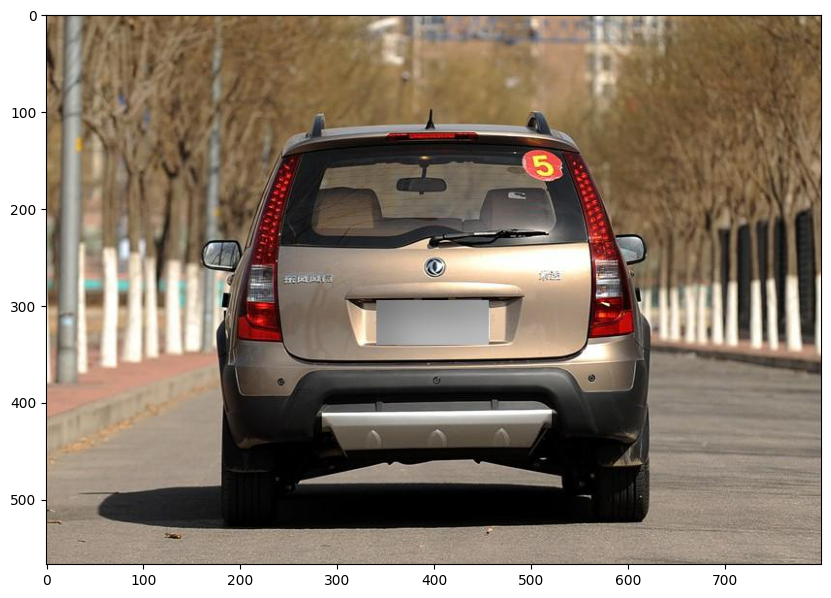

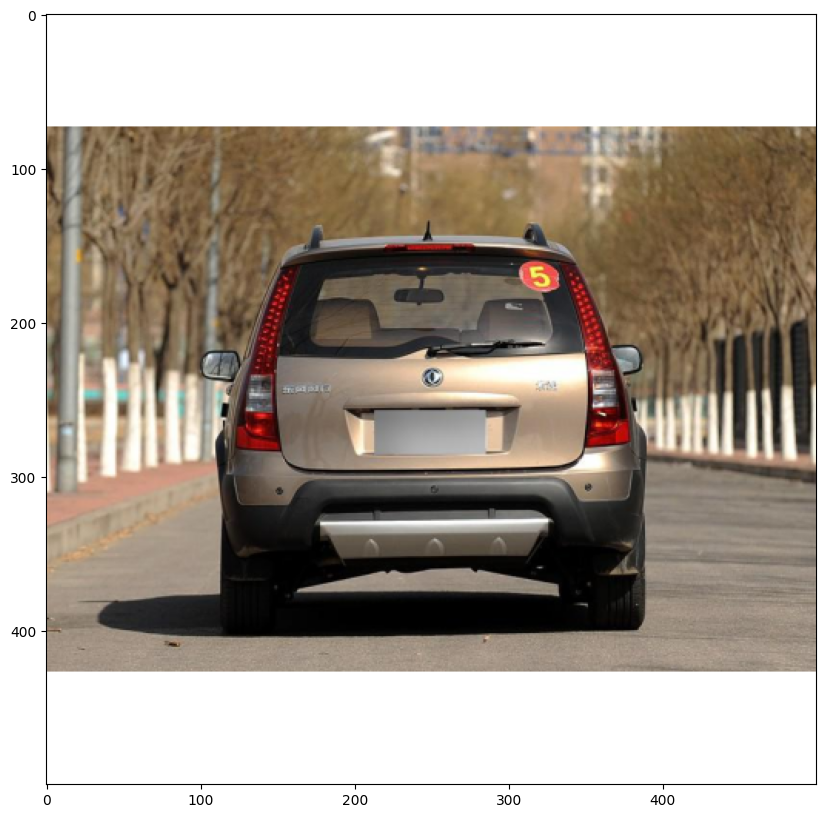

In [27]:
file_paths = []
for root, dirs, files in os.walk(IMG_DIR):
    for file in files:
        file_paths.append(os.path.join(root, file))



random_file = random.choice(image_paths)

img = cv2.cvtColor(cv2.imread(random_file), cv2.COLOR_BGR2RGB)
plt.imshow(img)
plt.show()

padded_image = ResizeAndPad(img, target_size=(500, 500), padding_color=(0, 0, 0),resize=True)
plt.imshow(padded_image)
plt.show()


## PG

In [29]:
image_paths = np.array([file for file in Path(IMG_DIR).rglob('*') if file.is_file()])
label_paths = np.array([file for file in Path(LAB_DIR).rglob('*') if file.is_file()])
makes = np.array([image_paths[i].parts[-4] for i in range(len(image_paths))])
models = np.array([image_paths[i].parts[-3] for i in range(len(image_paths))])
views = [open(label_paths[i], 'r').read().strip()[0] for i in range(len(label_paths))]

In [48]:
class CarDataset(Dataset):
    def __init__(self, 
                 image_paths, 
                 makes, 
                 models, 
                 views, 
                 transform=None, 
                 p_same_make=.9):
        """
        Args:
            image_paths (list or array): Paths to all images in the dataset.
            makes (list or array): Corresponding car makes for each image.
            models (list or array): Corresponding car models for each image.
            views (list or array): Corresponding views for each image.
            transform (callable, optional): Optional transform to apply to images.
            p_same_make (float): Probability of choosing a pair with the same make.
        """
        self.image_paths = image_paths
        self.makes = makes
        self.models = models
        self.views = views
        self.transform = transform
        
        self.p_same_make = p_same_make
        
        # Group image paths by make for efficient sampling
        self.grouped_by_make = defaultdict(list)
        for img_path, make in zip(image_paths, makes):
            self.grouped_by_make[make].append(img_path)
    
    def __len__(self):
        return len(self.image_paths)
    
    def __getitem__(self, index):
        # Get first image and its labels
        img1_path = self.image_paths[index]
        make1 = self.makes[index]
        model1 = self.models[index]
        view1 = self.views[index]
        
        # Determine if the pair should have the same make
        is_same_make = self.p_same_make > -1 and np.random.uniform(0, 1) < self.p_same_make
        
        # Sample second image
        if is_same_make:
            img2_path = random.choice(self.grouped_by_make[make1])
            make2 = make1
        else:
            make2 = random.choice([m for m in self.grouped_by_make.keys() if m != make1])
            img2_path = random.choice(self.grouped_by_make[make2])
        
        # Find labels for second image
        index2 = self.image_paths.tolist().index(img2_path)
        model2 = self.models[index2]
        view2 = self.views[index2]
        
        # Load and transform images
        # img1 = Image.open(img1_path).convert('RGB')
        # img2 = Image.open(img2_path).convert('RGB')

        img1 = str(img1_path)
        img2 = str(img2_path)
        if self.transform:
            img1 = self.transform(img1)
            img2 = self.transform(img2)
        
        # Create labels
        same_make_label = int(make1 == make2)
        same_model_label = int(model1 == model2)
        same_view_label = int(view1 == view2)
        
        return img1, img2, same_make_label, same_model_label, same_view_label


In [66]:

dataset = CarDataset(image_paths, makes, models, views, transform=None, p_same_make=0.5)

dataloader = DataLoader(dataset, batch_size=1, shuffle=True)

a = 0
my_list = []
for img1, img2, same_make, same_model, same_view in dataloader:
    my_list.append([img1, img2, same_make])
    a += 1
    if a == 1000:
        break


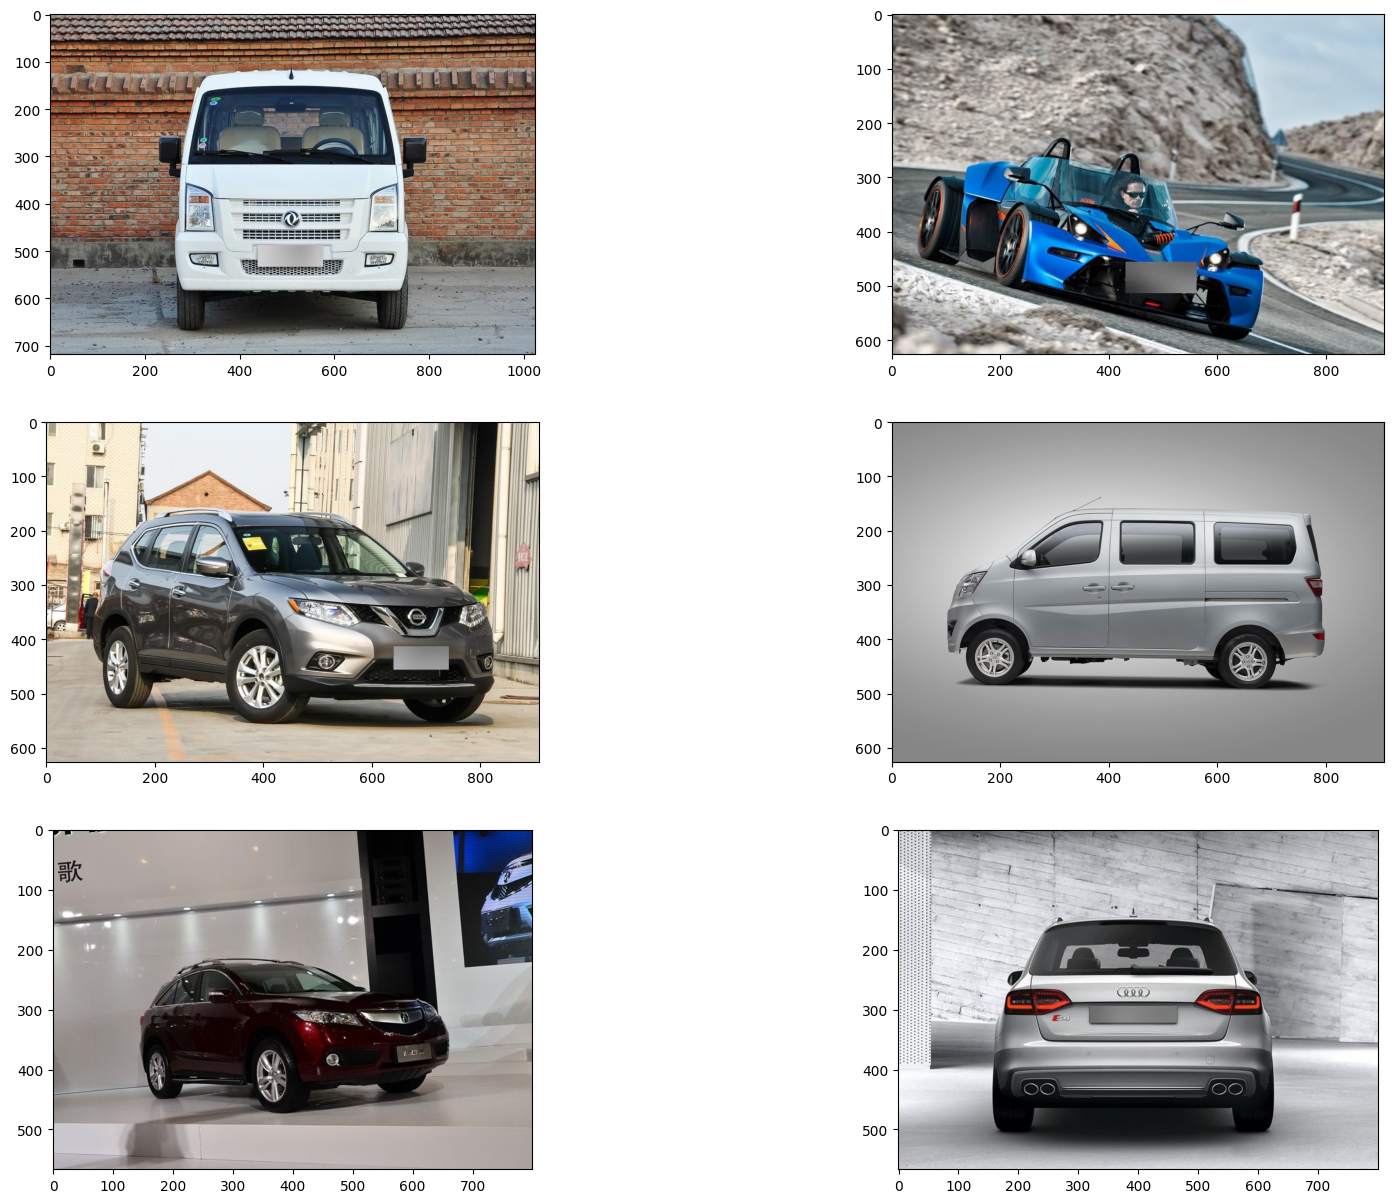

In [86]:
maxx =3
counter = 0
fig, ax = plt.subplots(maxx, 2, figsize=(20, 15))

for idx, (im1, im2, lbl) in enumerate(my_list[30:]):
    if not lbl:
        ax[counter,0].imshow(cv2.cvtColor(cv2.imread(im1[0]), cv2.COLOR_BGR2RGB))
        ax[counter,1].imshow(cv2.cvtColor(cv2.imread(im2[0]), cv2.COLOR_BGR2RGB))
        counter += 1
    
    if counter == maxx:
        break
    

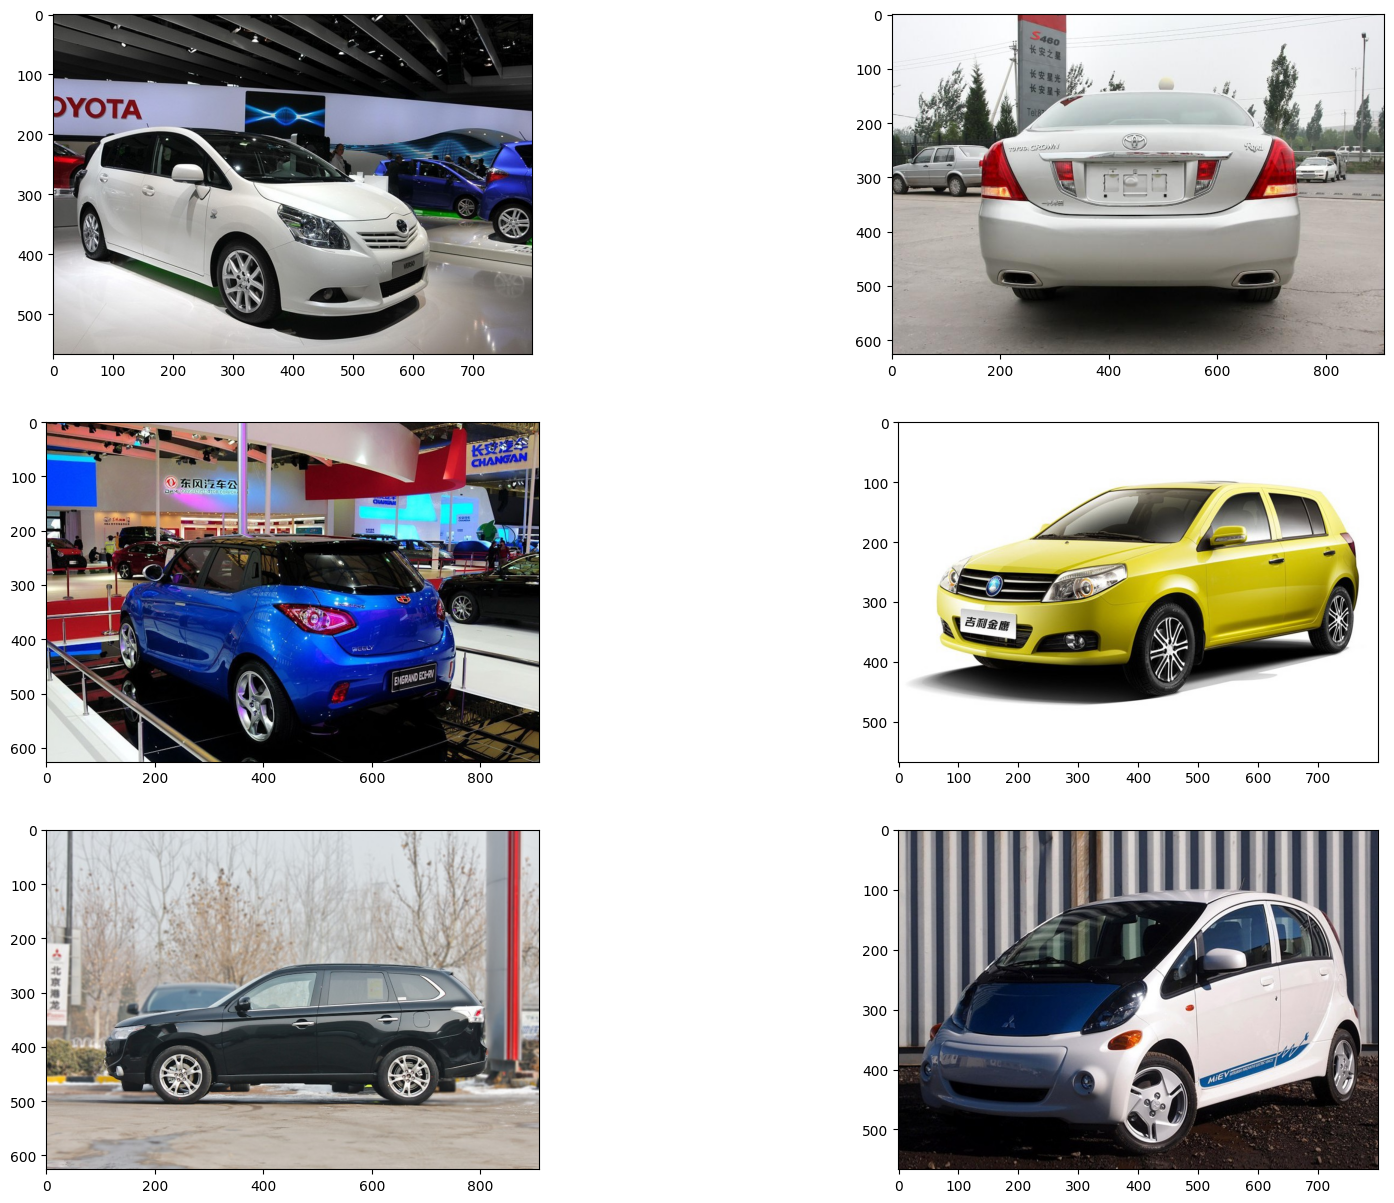

In [ ]:
maxx =3
counter = 0
fig, ax = plt.subplots(maxx, 2, figsize=(20, 15))

for idx, (im1, im2, lbl) in enumerate(my_list[30:]):
    if lbl:
        ax[counter,0].imshow(cv2.cvtColor(cv2.imread(im1[0]), cv2.COLOR_BGR2RGB))
        ax[counter,1].imshow(cv2.cvtColor(cv2.imread(im2[0]), cv2.COLOR_BGR2RGB))
        counter += 1
    
    if counter == maxx:
        break


(array([256.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0., 244.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <BarContainer object of 10 artists>)

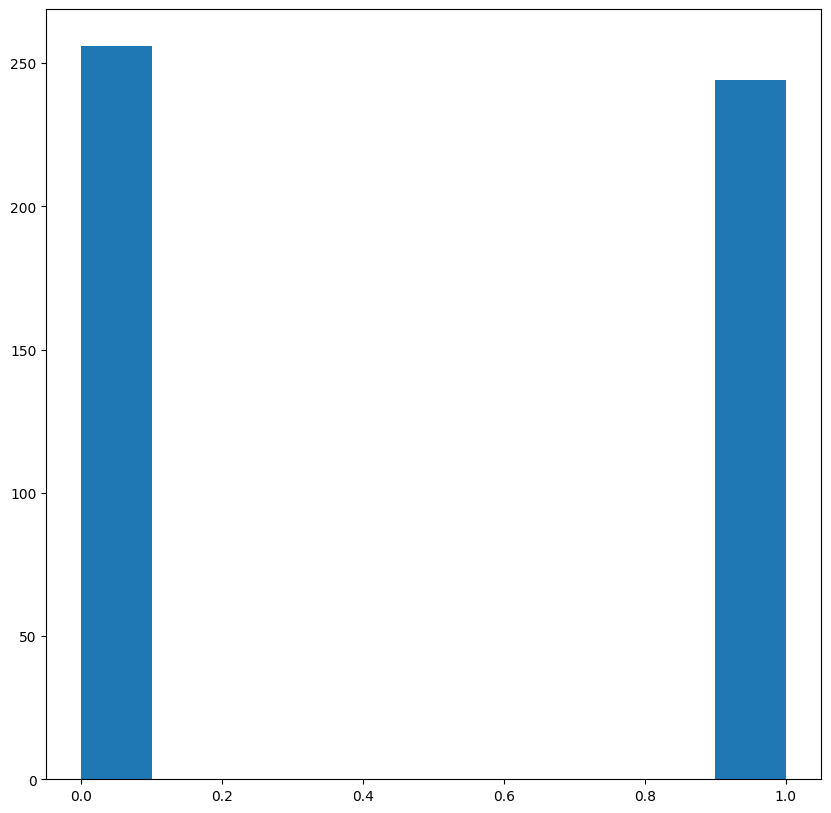

In [85]:
maxx = 500
counter = 0

histt = []
for idx, (im1, im2, lbl) in enumerate(my_list):

    histt.append(int(lbl))
    counter += 1
    if counter == maxx:
        break

plt.hist(histt)

In [42]:
# fixing resize and pad

from PIL import Image


def ResizeAndPad(image, target_size=(256, 256), padding_color=(0, 0, 0), resize=True, pil = True):
    """
    Pads or resizes an image to a target size while maintaining its aspect ratio.
    
    Args:
        image (numpy.ndarray): Input image (H x W x C).
        target_size (tuple): Target size as (width, height).
        padding_color (tuple): Color of padding (default black) as (B, G, R).
        resize (bool): If True, resizes the image to fit within the target size before padding. 
                        If False, only adds padding to match the target size without resizing.
                        The target size must be greater than or equal to the original size if resizing is False.
        pil (bool): If True, accepts PIL images and returns a PIL image.
                        If False, accepts numpy arrays and returns a numpy array.
    
    Returns:
        numpy.ndarray: Image padded or resized and padded to the target size.
    
    Notes:
        - The `INTER_AREA` interpolation method is used for resizing. It reduces aliasing effects while downsampling by averaging pixel values with respect to the overlapping area of the pixels.
    """

    if pil:
        image = np.array(image)
    target_width, target_height = target_size
    original_height, original_width = image.shape[:2]

    if not resize:
        if original_width > target_width or original_height > target_height:
            raise ValueError("Target size must be greater than or equal to the original size when resizing is disabled.")

        new_width, new_height = original_width, original_height
    else:
        # Calculate scaling factor to fit the image within the target size
        scale = min(target_width / original_width, target_height / original_height)
        new_width = max(int(original_width * scale), 1)
        new_height = max(int(original_height * scale), 1)

    if resize:
        resized_image = cv2.resize(image, (new_width, new_height), interpolation=cv2.INTER_AREA)
        
    else:
        resized_image = image

    padded_image = np.full((target_height, target_width, 3), padding_color, dtype=np.uint8)

    x_offset = (target_width - new_width) // 2
    y_offset = (target_height - new_height) // 2

    padded_image[y_offset:y_offset+new_height, x_offset:x_offset+new_width] = resized_image

    if pil:
        padded_image = Image.fromarray(padded_image)
    return padded_image




random_image =  np.random.randint(0, 256, (250, 300, 3), dtype=np.uint8)
pil_image = Image.fromarray(random_image)  # Convert NumPy array (OpenCV image) to PIL
#   # High-quality downscaling

plt.imshow(ResizeAndPad(pil_image, (350, 400), (0, 0, 0), resize=True))

AttributeError: 'DataLoader' object has no attribute 'as_numpy_iterator'

In [32]:
# shuffle, split

# def prepare_labels():

VerTr = pd.read_csv(os.path.join(SPLITS_DIR, "verification_train.txt"), sep="/", header=None, names=["make", "model","year", "fname"]).drop("year", axis=1)
# TestE = pd.read_csv(os.path.join(SPLITS_DIR, "verification_pairs_easy.txt"), sep=r'[/ ]', header=None, engine="python", names=["make1", "mod1","y1", "fname1", "make2", "mod2", "y2", "fname2", "lab"])#.drop("y1", "y2", axis=1)

In [33]:
# my_dir = "/home/kia/Desktop/PoD/NNDL/Data/"

# downloader(To = my_dir)

# combine_zips("data.zip", "combined.zip", my_dir)

# unzip_file(my_dir+"combined.zip", "d89551fd190e38", my_dir+"combined")

In [34]:
SPLITS_DIR

easy = pd.read_csv(os.path.join(SPLITS_DIR, 'verification_pairs_easy.txt'), header=None, names=['im1', 'im2', 'label'], delimiter=' ')
hard = pd.read_csv(os.path.join(SPLITS_DIR, 'verification_pairs_hard.txt'))
medium = pd.read_csv(os.path.join(SPLITS_DIR, 'verification_pairs_medium.txt'))

easy.head()

verification_pairs_easy.txt
verification_pairs_hard.txt
verification_pairs_medium.txt
verification_train.txt


In [ ]:
import os, random
from PIL import Image
from torch.utils.data import Dataset
import torchvision.transforms as T

class FlexibleDataset(Dataset):
    def __init__(self, root, transform=None, mode="contrastive"):
        self.root = root
        self.mode = mode
        self.transform = transform or T.Compose([
            T.Resize((128,128)),
            T.ToTensor()
        ])
        # collect samples + labels
        self.samples, self.labels = [], []
        makes = sorted(os.listdir(root))
        self.make_to_id = {m:i for i,m in enumerate(makes)}
        for m in makes:
            m_dir = os.path.join(root,m)
            if not os.path.isdir(m_dir): continue
            for model in os.listdir(m_dir):
                model_dir = os.path.join(m_dir,model)
                if not os.path.isdir(model_dir): continue
                for f in os.listdir(model_dir):
                    if f.endswith(".jpg"):
                        self.samples.append(os.path.join(model_dir,f))
                        self.labels.append(self.make_to_id[m])
        self.label_to_indices = {}
        for idx,l in enumerate(self.labels):
            self.label_to_indices.setdefault(l,[]).append(idx)

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        if self.mode == "contrastive":
            # pick base sample
            img1_path, label1 = self.samples[idx], self.labels[idx]
            if random.random() < 0.5:
                # positive
                idx2 = random.choice(self.label_to_indices[label1])
                label = 1
            else:
                # negative
                neg_label = random.choice([l for l in self.label_to_indices if l != label1])
                idx2 = random.choice(self.label_to_indices[neg_label])
                label = 0
            img2_path = self.samples[idx2]
            img1 = self.transform(Image.open(img1_path).convert("RGB"))
            img2 = self.transform(Image.open(img2_path).convert("RGB"))
            return img1, img2, label

        elif self.mode == "triplet":
            # anchor
            anchor_path, label = self.samples[idx], self.labels[idx]
            # positive
            pos_idx = random.choice(self.label_to_indices[label])
            pos_path = self.samples[pos_idx]
            # negative
            neg_label = random.choice([l for l in self.label_to_indices if l != label])
            neg_idx = random.choice(self.label_to_indices[neg_label])
            neg_path = self.samples[neg_idx]
            # load images
            anchor = self.transform(Image.open(anchor_path).convert("RGB"))
            positive = self.transform(Image.open(pos_path).convert("RGB"))
            negative = self.transform(Image.open(neg_path).convert("RGB"))
            return anchor, positive, negative


In [ ]:
# CompCars-aware Siamese/Triplet Dataset with bbox crop and same-view option
import os, random
from collections import defaultdict
from PIL import Image
from torch.utils.data import Dataset
import torchvision.transforms as T

class CompCarsSiameseDataset(Dataset):
    def __init__(self,
                 image_root,
                 label_root,
                 transform=None,
                 mode="contrastive",           # "contrastive" or "triplet"
                 require_same_view=False,      # ensure positives share the same view
                 bbox_crop=True):
        assert mode in ("contrastive", "triplet")
        self.image_root = image_root
        self.label_root = label_root
        self.mode = mode
        self.require_same_view = require_same_view
        self.bbox_crop = bbox_crop
        self.transform = transform or T.Compose([T.Resize((128,128)), T.ToTensor()])

        # --- collect (img_path, label(make_id), view, bbox) ---
        samples = []
        makes = sorted(os.listdir(image_root))
        self.make_to_id = {m:i for i,m in enumerate(makes)}
        for m in makes:
            m_dir = os.path.join(image_root, m)
            if not os.path.isdir(m_dir): continue
            for model in os.listdir(m_dir):
                model_dir = os.path.join(m_dir, model)
                if not os.path.isdir(model_dir): continue
                for year in os.listdir(model_dir):
                    year_dir = os.path.join(model_dir, year)
                    if not os.path.isdir(year_dir): continue
                    for fn in os.listdir(year_dir):
                        if not fn.lower().endswith((".jpg", ".jpeg", ".png")): continue
                        img_path = os.path.join(year_dir, fn)
                        # corresponding label file: same relative path under label_root, .txt
                        lbl_path = os.path.join(label_root, m, model, year, os.path.splitext(fn)[0] + ".txt")
                        view = None
                        bbox = None
                        try:
                            with open(lbl_path, "r") as fh:
                                toks = fh.read().split()
                                if len(toks) >= 6:
                                    view = int(toks[0])
                                    # toks[1] is number-of-cars (ignored)
                                    x1, y1, x2, y2 = map(int, toks[2:6])
                                    bbox = (x1, y1, x2, y2)
                        except FileNotFoundError:
                            # no label file: leave view/bbox as None
                            pass
                        samples.append({
                            "img_path": img_path,
                            "label": self.make_to_id[m],
                            "view": view,
                            "bbox": bbox
                        })

        # --- optionally filter to ensure same-view positives are possible ---
        # build (label,view) -> indices mapping
        def build_maps(samples_list):
            label_to_indices = defaultdict(list)
            label_view_to_indices = defaultdict(list)
            view_label_to_indices = defaultdict(lambda: defaultdict(list))
            for i, s in enumerate(samples_list):
                lab, vw = s["label"], s["view"]
                label_to_indices[lab].append(i)
                label_view_to_indices[(lab, vw)].append(i)
                view_label_to_indices[vw][lab].append(i)
            return label_to_indices, label_view_to_indices, view_label_to_indices

        label_to_indices, label_view_to_indices, view_label_to_indices = build_maps(samples)

        if require_same_view:
            keep = [i for i, s in enumerate(samples)
                    if len(label_view_to_indices[(s["label"], s["view"])]) > 1]
            # rebuild samples & maps using kept indices
            samples = [samples[i] for i in keep]
            label_to_indices, label_view_to_indices, view_label_to_indices = build_maps(samples)

        self.samples = samples
        self.label_to_indices = label_to_indices
        self.label_view_to_indices = label_view_to_indices
        self.view_label_to_indices = view_label_to_indices
        self.labels = [s["label"] for s in samples]

    def __len__(self):
        return len(self.samples)

    def _load_and_crop(self, sample):
        img = Image.open(sample["img_path"]).convert("RGB")
        if self.bbox_crop and sample["bbox"] is not None:
            x1, y1, x2, y2 = sample["bbox"]
            # clamp bbox to image bounds
            w, h = img.size
            x1, y1 = max(0, x1), max(0, y1)
            x2, y2 = min(w, x2), min(h, y2)
            if x2 > x1 and y2 > y1:
                img = img.crop((x1, y1, x2, y2))
        return self.transform(img)

    def __getitem__(self, idx):
        if self.mode == "contrastive":
            a = self.samples[idx]
            lab_a, view_a = a["label"], a["view"]

            # choose positive or negative
            if random.random() < 0.5:
                # positive: same label (prefer same view if required)
                if self.require_same_view:
                    pool = [i for i in self.label_view_to_indices[(lab_a, view_a)] if i != idx]
                    if not pool:  # fallback to any same-label sample
                        pool = [i for i in self.label_to_indices[lab_a] if i != idx]
                else:
                    pool = [i for i in self.label_to_indices[lab_a] if i != idx]
                if not pool:
                    # rare case: no other sample of same label -> use anchor itself (will give zero dist)
                    idx2 = idx
                else:
                    idx2 = random.choice(pool)
                label = 1
            else:
                # negative: different label (prefer same view if required)
                if self.require_same_view:
                    # pick a different label that exists in the same view
                    labels_in_view = list(self.view_label_to_indices[view_a].keys())
                    neg_labels = [l for l in labels_in_view if l != lab_a]
                    if not neg_labels:
                        # fallback to any different label
                        neg_labels = [l for l in self.label_to_indices.keys() if l != lab_a]
                    neg_label = random.choice(neg_labels)
                    idx2 = random.choice(self.view_label_to_indices[view_a][neg_label]) if view_a in self.view_label_to_indices and neg_label in self.view_label_to_indices[view_a] else random.choice(self.label_to_indices[neg_label])
                else:
                    neg_label = random.choice([l for l in self.label_to_indices.keys() if l != lab_a])
                    idx2 = random.choice(self.label_to_indices[neg_label])
                label = 0

            b = self.samples[idx2]
            img1 = self._load_and_crop(a)
            img2 = self._load_and_crop(b)
            return img1, img2, label

        else:  # triplet mode: return (anchor, positive, negative)
            anchor = self.samples[idx]
            lab_a, view_a = anchor["label"], anchor["view"]
            # positive
            if self.require_same_view:
                pos_pool = [i for i in self.label_view_to_indices[(lab_a, view_a)] if i != idx]
                if not pos_pool:
                    pos_pool = [i for i in self.label_to_indices[lab_a] if i != idx]
            else:
                pos_pool = [i for i in self.label_to_indices[lab_a] if i != idx]
            pos_idx = random.choice(pos_pool) if pos_pool else idx
            # negative (different label)
            if self.require_same_view:
                labels_in_view = list(self.view_label_to_indices[view_a].keys())
                neg_labels = [l for l in labels_in_view if l != lab_a]
                if not neg_labels:
                    neg_labels = [l for l in self.label_to_indices.keys() if l != lab_a]
                neg_label = random.choice(neg_labels)
                neg_idx = random.choice(self.view_label_to_indices[view_a][neg_label]) if view_a in self.view_label_to_indices and neg_label in self.view_label_to_indices[view_a] else random.choice(self.label_to_indices[neg_label])
            else:
                neg_label = random.choice([l for l in self.label_to_indices.keys() if l != lab_a])
                neg_idx = random.choice(self.label_to_indices[neg_label])
            return (self._load_and_crop(anchor),
                    self._load_and_crop(self.samples[pos_idx]),
                    self._load_and_crop(self.samples[neg_idx]))


In [ ]:
class TripletLoss(nn.Module):
    def __init__(self, margin=1.0):
        super().__init__()
        self.margin = margin

    def forward(self, anchor, positive, negative):
        # embeddings: (batch, d)
        d_pos = F.pairwise_distance(anchor, positive)  # anchor → positive
        d_neg = F.pairwise_distance(anchor, negative)  # anchor → negative
        loss = F.relu(d_pos - d_neg + self.margin)
        return torch.mean(loss)


In [ ]:
# class SiameseDataset(Dataset):
#     def __init__(self, root, transform=None):
#         self.root = root
#         self.transform = transform or T.Compose([
#             T.Resize((128,128)),
#             # T.Grayscale(num_output_channels=3),
#             T.ToTensor()
#         ])
#         # collect image paths + make_id labels
#         self.samples, self.labels = [], []
#         makes = sorted(os.listdir(root))
#         self.make_to_id = {m:i for i,m in enumerate(makes)}
#         for m in makes:
#             m_dir = os.path.join(root,m)
#             if not os.path.isdir(m_dir): continue
#             for model in os.listdir(m_dir):
#                 model_dir = os.path.join(m_dir,model)
#                 if not os.path.isdir(model_dir): continue
#                 for year in os.listdir(model_dir):
#                     year_dir = os.path.join(model_dir,year)
#                     if not os.path.isdir(year_dir): continue
#                     for f in os.listdir(year_dir):
#                         if f.endswith(".jpg"):
#                             self.samples.append(os.path.join(year_dir,f))
#                             self.labels.append(self.make_to_id[m])
#         # map label → indices
#         self.label_to_indices = {}
#         for idx,l in enumerate(self.labels):
#             self.label_to_indices.setdefault(l,[]).append(idx)

#     def __len__(self):
#         return len(self.samples)

#     def __getitem__(self, idx):
#         img1_path, label1 = self.samples[idx], self.labels[idx]
#         # decide pos/neg pair
#         if random.random() < 0.5:
#             # positive pair
#             idx2 = random.choice(self.label_to_indices[label1])
#             label = 1
#         else:
#             # negative pair
#             neg_label = random.choice([l for l in self.label_to_indices if l != label1])
#             idx2 = random.choice(self.label_to_indices[neg_label])
#             label = 0
#         img2_path = self.samples[idx2]

#         img1 = self.transform(Image.open(img1_path).convert("RGB"))
#         img2 = self.transform(Image.open(img2_path).convert("RGB"))

#         return img1, img2, label



# === Siamese dataset with bbox cropping and same-view sampling (contrastive mode) ===







# class SiameseDatasetBBox(Dataset):
#     """
#     image_root: root folder containing images (image/make/model/year/xxx.jpg)
#     label_root: root folder containing label txts (label/make/model/year/xxx.txt)
#     same_view: if True, both images in each pair will have the same view id (if available)
#     transform: applied AFTER cropping
#     """
#     def __init__(self, image_root, label_root, transform=None, same_view=False):
#         self.image_root = image_root
#         self.label_root = label_root
#         self.same_view = same_view
#         self.transform = transform or T.Compose([ResizePad((240,240)), T.ToTensor()])

#         self.items = []  # list of dicts: {'img_path','make_id','view','bbox'}
#         self.make_to_id = {}
#         makes = sorted(os.listdir(image_root))
#         # map makes to ids (only directories)
#         for i,m in enumerate(makes):
#             if os.path.isdir(os.path.join(image_root,m)):
#                 self.make_to_id[m] = len(self.make_to_id)

#         # collect images + metadata
#         for m in sorted(os.listdir(image_root)):
#             m_dir = os.path.join(image_root, m)
#             if not os.path.isdir(m_dir): continue
#             for model in sorted(os.listdir(m_dir)):
#                 model_dir = os.path.join(m_dir, model)
#                 if not os.path.isdir(model_dir): continue
#                 for year in sorted(os.listdir(model_dir)):
#                     year_dir = os.path.join(model_dir, year)
#                     if not os.path.isdir(year_dir): continue
#                     for fn in sorted(os.listdir(year_dir)):
#                         if not fn.lower().endswith(('.jpg','.jpeg','.png')): 
#                             continue
#                         img_path = os.path.join(year_dir, fn)
#                         # build matching label path by preserving relative subpath and switching ext to .txt
#                         rel = os.path.relpath(img_path, image_root)                # make/model/year/xxx.jpg
#                         lbl_rel = os.path.splitext(rel)[0] + ".txt"                # make/model/year/xxx.txt
#                         lbl_path = os.path.join(label_root, lbl_rel)
#                         view = None
#                         bbox = None
#                         if os.path.isfile(lbl_path):
#                             try:
#                                 with open(lbl_path, 'r') as fh:
#                                     lines = [l.strip() for l in fh if l.strip()]
#                                 if len(lines) >= 1:
#                                     # first token on first non-empty line is view id
#                                     view = int(lines[0].split()[0])
#                                 # bbox often on third line per your example; try line 3 then fallback to line2
#                                 bbox_line = None
#                                 if len(lines) >= 3:
#                                     bbox_line = lines[2]
#                                 elif len(lines) >= 2 and len(lines[1].split()) >= 4:
#                                     bbox_line = lines[1]
#                                 if bbox_line:
#                                     toks = bbox_line.split()
#                                     if len(toks) >= 4:
#                                         bbox = list(map(int, toks[:4]))
#                             except Exception:
#                                 # if parsing fails, leave view/bbox as None
#                                 view = view
#                                 bbox = bbox
#                         make_id = self.make_to_id.get(m, None)
#                         if make_id is None:
#                             # skip unknown make dirs
#                             continue
#                         self.items.append({'img_path': img_path, 'make_id': make_id, 'view': view, 'bbox': bbox})

#         # Build index maps for sampling
#         self.label_to_indices = {}               # make_id -> [idx...]
#         self.label_view_to_indices = {}          # (make_id, view) -> [idx...]
#         self.views_set = set()
#         for idx, it in enumerate(self.items):
#             L = it['make_id']
#             V = it['view']
#             self.label_to_indices.setdefault(L, []).append(idx)
#             self.label_view_to_indices.setdefault((L, V), []).append(idx)
#             if V is not None:
#                 self.views_set.add(V)

#         # convenience lists
#         self.make_ids = list(self.label_to_indices.keys())

#     def __len__(self):
#         return len(self.items)

#     def __getitem__(self, idx):
#         # base sample
#         it1 = self.items[idx]
#         img1 = Image.open(it1['img_path']).convert("RGB")
#         img1 = _safe_crop(img1, it1['bbox'])
#         if self.transform: img1 = self.transform(img1)
#         L1 = it1['make_id']
#         V1 = it1['view']

#         # decide positive or negative (50/50)
#         if random.random() < 0.5:
#             # positive: same make, and if same_view requested require same view (if possible)
#             if self.same_view and V1 is not None:
#                 candidates = self.label_view_to_indices.get((L1, V1), [])
#                 # remove self
#                 candidates = [i for i in candidates if i != idx]
#                 if not candidates:
#                     # fallback to any same-make image
#                     candidates = [i for i in self.label_to_indices[L1] if i != idx]
#             else:
#                 candidates = [i for i in self.label_to_indices[L1] if i != idx]
#             # if still empty (single image of that make) then sample another index of same make (allow same idx)
#             if not candidates:
#                 idx2 = idx
#             else:
#                 idx2 = random.choice(candidates)
#             label = 1
#         else:
#             # negative: different make
#             if self.same_view and V1 is not None:
#                 # prefer different makes that have the same view
#                 candidate_makes = [m for m in self.make_ids if m != L1 and (m, V1) in self.label_view_to_indices]
#                 if candidate_makes:
#                     neg_make = random.choice(candidate_makes)
#                     neg_candidates = self.label_view_to_indices[(neg_make, V1)]
#                     idx2 = random.choice(neg_candidates)
#                 else:
#                     # fallback: any different make
#                     neg_makes = [m for m in self.make_ids if m != L1]
#                     neg_make = random.choice(neg_makes)
#                     idx2 = random.choice(self.label_to_indices[neg_make])
#             else:
#                 neg_makes = [m for m in self.make_ids if m != L1]
#                 neg_make = random.choice(neg_makes)
#                 idx2 = random.choice(self.label_to_indices[neg_make])
#             label = 0

#         it2 = self.items[idx2]
#         img2 = Image.open(it2['img_path']).convert("RGB")
#         img2 = _safe_crop(img2, it2['bbox'])
#         if self.transform: img2 = self.transform(img2)

#         return img1, img2, label


In [ ]:
for name, param in model.named_parameters():
    print(name, param.requires_grad)


trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
print(f"Trainable: {trainable_params}, Total: {total_params}")


feature.0.weight True
feature.1.weight True
feature.1.bias True
feature.4.0.conv1.weight True
feature.4.0.bn1.weight True
feature.4.0.bn1.bias True
feature.4.0.conv2.weight True
feature.4.0.bn2.weight True
feature.4.0.bn2.bias True
feature.4.1.conv1.weight True
feature.4.1.bn1.weight True
feature.4.1.bn1.bias True
feature.4.1.conv2.weight True
feature.4.1.bn2.weight True
feature.4.1.bn2.bias True
feature.5.0.conv1.weight True
feature.5.0.bn1.weight True
feature.5.0.bn1.bias True
feature.5.0.conv2.weight True
feature.5.0.bn2.weight True
feature.5.0.bn2.bias True
feature.5.0.downsample.0.weight True
feature.5.0.downsample.1.weight True
feature.5.0.downsample.1.bias True
feature.5.1.conv1.weight True
feature.5.1.bn1.weight True
feature.5.1.bn1.bias True
feature.5.1.conv2.weight True
feature.5.1.bn2.weight True
feature.5.1.bn2.bias True
feature.6.0.conv1.weight True
feature.6.0.bn1.weight True
feature.6.0.bn1.bias True
feature.6.0.conv2.weight True
feature.6.0.bn2.weight True
feature.6.0.b